In [1]:
from google.colab import files

uploaded = files.upload()

Saving german_credit.csv to german_credit.csv


# FairCredit: Algorithmic Bias Auditing and Mitigation in Digital Micro-Lending

This notebook demonstrates a complete workflow to audit and mitigate algorithmic bias in a micro-lending risk assessment model using the German Credit dataset.

In [2]:
!pip install -q fairlearn

## 1. Dataset Loading and Exploratory Data Analysis

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('german_credit.csv')

# Display basic details
print(f"Dataset Shape: {df.shape}")
display(df.head())

print("\n--- Column Information and Data Types ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Dataset Shape: (1000, 21)


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age_years,other_installment_plans,housing,existing_credits,job,liable_people,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,good
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,bad
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,good
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,good
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,bad



--- Column Information and Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_account         1000 non-null   object
 1   duration_months          1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings_account          1000 non-null   object
 6   employment_since         1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age_years                1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14

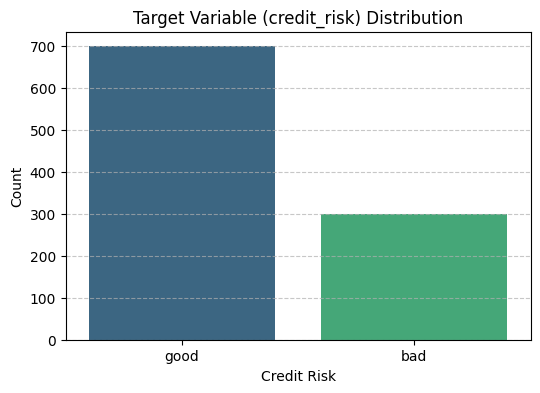

In [4]:
# Plot Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='credit_risk', palette='viridis', hue='credit_risk', legend=False)
plt.title('Target Variable (credit_risk) Distribution')
plt.xlabel('Credit Risk')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 2. Data Preprocessing

We will extract the target variable, separate our features, and define the sensitive attribute `personal_status_sex` based on the specified group mapping:
- **Female**: `A92`, `A95`
- **Male**: `A91`, `A93`, `A94`

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define seed for reproducibility
RANDOM_SEED = 42

# Target column mapping: standardizing to 1 (good - positive class) and 0 (bad)
y = df['credit_risk'].map({'good': 1, 'bad': 0})
X = df.drop(columns=['credit_risk'])

# Establish sensitive attribute mapping from personal_status_sex column
# If column doesn't match perfectly, handle case-insensitively or defaults safely
sex_col = 'personal_status_sex'

def map_gender(val):
    if val in ['A92', 'A95']:
        return 'Female'
    elif val in ['A91', 'A93', 'A94']:
        return 'Male'
    else:
        return 'Unknown'

# Store sensitive attribute separate from X to test fairness, but we remove it from X to demonstrate a key concept
sensitive_attr = X[sex_col].apply(map_gender)

# Drop sensitive attribute from modeling features to show why "Fairness through Blindness" is not sufficient
X_features = X.drop(columns=[sex_col])

# Split into stratified train, validation, and test sets
X_train_raw, X_temp_raw, y_train, y_temp, sens_train, sens_temp = train_test_split(
    X_features, y, sensitive_attr, test_size=0.3, random_state=RANDOM_SEED, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test, sens_val, sens_test = train_test_split(
    X_temp_raw, y_temp, sens_temp, test_size=0.5, random_state=RANDOM_SEED, stratify=y_temp
)

# Identity numerical and categorical columns
num_cols = X_features.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_features.select_dtypes(exclude=[np.number]).columns.tolist()

# Create transformer pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Fit on training data only to avoid data leakage
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"Preprocessed train shape: {X_train.shape}")
print(f"Preprocessed val shape: {X_val.shape}")
print(f"Preprocessed test shape: {X_test.shape}")

Preprocessed train shape: (700, 57)
Preprocessed val shape: (150, 57)
Preprocessed test shape: (150, 57)


## 3. Machine Learning Baseline Model Training & Evaluation

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Initialize and train primary baseline model
model = LogisticRegression(random_state=RANDOM_SEED, max_iter=1000)
model.fit(X_train, y_train)

# Predict on validation set
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]

# Evaluation Metrics Helper
def print_metrics(y_true, y_pred, y_proba, title="Model Evaluation"):
    print(f"=== {title} ===")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_proba):.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

print_metrics(y_val, y_val_pred, y_val_proba, "Logistic Regression Baseline (Validation Set)")

=== Logistic Regression Baseline (Validation Set) ===
Accuracy:  0.7467
Precision: 0.7863
Recall:    0.8762
F1-Score:  0.8288
ROC-AUC:   0.7524

Confusion Matrix:
[[20 25]
 [13 92]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.44      0.51        45
           1       0.79      0.88      0.83       105

    accuracy                           0.75       150
   macro avg       0.70      0.66      0.67       150
weighted avg       0.73      0.75      0.73       150



## 4. Algorithmic Fairness Auditing

We calculate performance and selection rates sliced by gender group utilizing Fairlearn's MetricFrame.

In [7]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

# Define metrics dictionary to run via MetricFrame
metrics = {
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate,
    'accuracy': accuracy_score
}

metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_val,
    y_pred=y_val_pred,
    sensitive_features=sens_val
)

print("=== Fairness Metrics by Demographic Group (Validation Set) ===")
display(metric_frame.by_group)

# Calculate structural difference and ratio parameters
dp_diff = demographic_parity_difference(y_val, y_val_pred, sensitive_features=sens_val)
dp_ratio = demographic_parity_ratio(y_val, y_val_pred, sensitive_features=sens_val)
eo_diff = equalized_odds_difference(y_val, y_val_pred, sensitive_features=sens_val)

print(f"Demographic Parity Difference: {dp_diff:.4f}")
print(f"Demographic Parity Ratio: {dp_ratio:.4f}")
print(f"Equalized Odds Difference: {eo_diff:.4f}")

=== Fairness Metrics by Demographic Group (Validation Set) ===


,selection_rate,tpr,fpr,accuracy
personal_status_sex,,,,
Female,0.773585,0.888889,0.529412,0.754717
Male,0.783505,0.869565,0.571429,0.742268


Demographic Parity Difference: 0.0099
Demographic Parity Ratio: 0.9873
Equalized Odds Difference: 0.0420


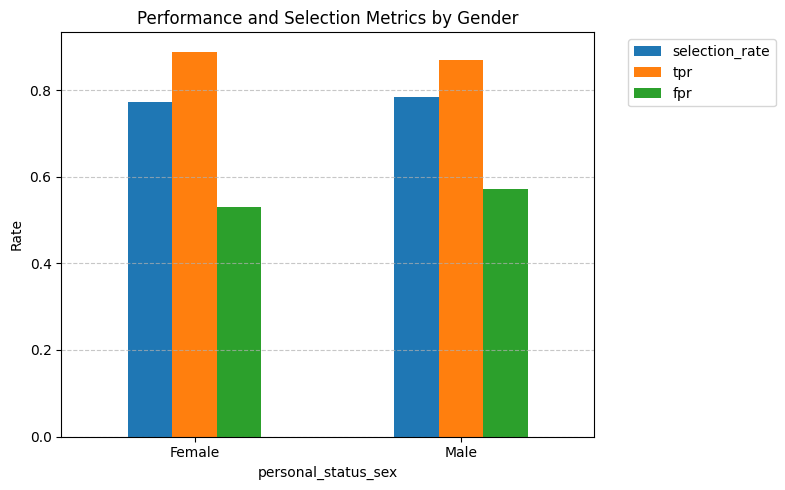

In [8]:
# Plot comparison metrics
metric_frame.by_group[['selection_rate', 'tpr', 'fpr']].plot(kind='bar', figsize=(8, 5))
plt.title('Performance and Selection Metrics by Gender')
plt.ylabel('Rate')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. Bias Mitigation using Fairlearn

We will implement a post-processing technique `ThresholdOptimizer` to find optimal, fair thresholds on validation predictions to satisfy equalized odds parity constraints.

In [9]:
from fairlearn.postprocessing import ThresholdOptimizer

# ThresholdOptimizer requires pre-computed predictions or an estimator
# Fit the post-processor to optimize rules based on validation dataset constraints
optimizer = ThresholdOptimizer(
    estimator=model,
    constraints="equalized_odds",
    predict_method='predict_proba'
)

optimizer.fit(X_train, y_train, sensitive_features=sens_train)

# Compare performance and fairness on the untouched test dataset
y_test_pred_base = model.predict(X_test)
y_test_proba_base = model.predict_proba(X_test)[:, 1]

y_test_pred_mitigated = optimizer.predict(X_test, sensitive_features=sens_test)

# Base performance audit
base_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_test_pred_base,
    sensitive_features=sens_test
)

# Mitigated performance audit
mitigated_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_test_pred_mitigated,
    sensitive_features=sens_test
)

print("=== BASELINE TEST METRICS ===")
display(base_metric_frame.by_group)
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test, y_test_pred_base, sensitive_features=sens_test):.4f}")
print(f"Equalized Odds Difference: {equalized_odds_difference(y_test, y_test_pred_base, sensitive_features=sens_test):.4f}")

print("\n=== MITIGATED TEST METRICS ===")
display(mitigated_metric_frame.by_group)
print(f"Demographic Parity Difference: {demographic_parity_difference(y_test, y_test_pred_mitigated, sensitive_features=sens_test):.4f}")
print(f"Equalized Odds Difference: {equalized_odds_difference(y_test, y_test_pred_mitigated, sensitive_features=sens_test):.4f}")

=== BASELINE TEST METRICS ===


,selection_rate,tpr,fpr,accuracy
personal_status_sex,,,,
Female,0.651163,0.740741,0.500000,0.651163
Male,0.757009,0.846154,0.517241,0.747664


Demographic Parity Difference: 0.1058
Equalized Odds Difference: 0.1054

=== MITIGATED TEST METRICS ===


,selection_rate,tpr,fpr,accuracy
personal_status_sex,,,,
Female,0.651163,0.740741,0.500000,0.651163
Male,0.738318,0.846154,0.448276,0.766355


Demographic Parity Difference: 0.0872
Equalized Odds Difference: 0.1054


In [10]:

# Find trained model and fairness-related objects in the notebook
for name, obj in list(globals().items()):
    try:
        module = type(obj).__module__
        has_predict = callable(getattr(obj, "predict", None))
        has_predict_proba = callable(getattr(obj, "predict_proba", None))

        if (
            has_predict
            and (
                module.startswith("sklearn")
                or module.startswith("fairlearn")
                or has_predict_proba
            )
        ):
            print(
                f"Variable: {name} | "
                f"Type: {type(obj).__name__} | "
                f"Module: {module}"
            )
    except Exception:
        pass


Variable: Pipeline | Type: ABCMeta | Module: abc
Variable: LogisticRegression | Type: type | Module: builtins
Variable: RandomForestClassifier | Type: ABCMeta | Module: abc
Variable: model | Type: LogisticRegression | Module: sklearn.linear_model._logistic
Variable: optimizer | Type: ThresholdOptimizer | Module: fairlearn.postprocessing._threshold_optimizer


In [11]:

# Inspect the fitted model and fairness optimizer
print("MODEL")
print("Type:", type(model))
print("Fitted:", hasattr(model, "classes_"))

print("\nOPTIMIZER")
print("Type:", type(optimizer))
print("Fitted:", hasattr(optimizer, "estimators_"))

print("\nPOSSIBLE PREPROCESSING PIPELINES")
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    try:
        if (
            type(obj).__name__ == "Pipeline"
            or type(obj).__name__ == "ColumnTransformer"
        ):
            print(name, "->", type(obj).__name__)
    except Exception:
        pass


MODEL
Type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Fitted: True

OPTIMIZER
Type: <class 'fairlearn.postprocessing._threshold_optimizer.ThresholdOptimizer'>
Fitted: False

POSSIBLE PREPROCESSING PIPELINES
num_transformer -> Pipeline
cat_transformer -> Pipeline
preprocessor -> ColumnTransformer


In [12]:

import joblib
import os
import sklearn
import fairlearn

os.makedirs("faircredit_artifacts", exist_ok=True)

joblib.dump(model, "faircredit_artifacts/baseline_model.joblib")
joblib.dump(optimizer, "faircredit_artifacts/fairness_optimizer.joblib")

metadata = {
    "project": "FairCredit",
    "baseline_model": "LogisticRegression",
    "mitigation": "ThresholdOptimizer",
    "scikit_learn_version": sklearn.__version__,
    "fairlearn_version": fairlearn.__version__,
}

joblib.dump(metadata, "faircredit_artifacts/metadata.joblib")

print("Saved model and optimizer artifacts.")


Saved model and optimizer artifacts.


In [13]:

from google.colab import files
import shutil

shutil.make_archive(
    "faircredit_artifacts",
    "zip",
    "faircredit_artifacts"
)

files.download("faircredit_artifacts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>